# Fase 2: Exploración, Análisis y Preprocesamiento de Datos
**Proyecto:** Clasificación de Resoluciones de Reclamos en el Servicio de Gas Natural (ENARGAS 2026)  
**Objetivo:** Cargar el conjunto de datos, verificar su integridad, analizar la agregación de `reclamo_cantidad` y preparar las transformaciones previas al modelado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Carga del conjunto de datos original
ruta_raw = '../data/raw/reclamos_prestadoras_2026.csv'
df = pd.read_csv(ruta_raw)

# Asignar ID único a cada registro agregado para garantizar trazabilidad
df['id_registro_agregado'] = df.index

print(f"Dimensiones de la matriz original: {df.shape[0]} registros agregados, {df.shape[1]} columnas")
print(f"Total acumulado de reclamos ponderados: {df['reclamo_cantidad'].sum():,}")

# Control de calidad y consistencia
print("\n--- Verificación de Integridad ---")
print(f"Valores nulos totales: {df.isnull().sum().sum()}")
print(f"Registros con reclamo_cantidad <= 0: {(df['reclamo_cantidad'] <= 0).sum()}")
print(f"Filas agregadas duplicadas exactas: {df.duplicated(subset=['reclamo_mes_nro', 'reclamo_prestadora', 'reclamo_provincia', 'reclamo_grupo', 'reclamo_via_ingreso', 'reclamo_resolucion']).sum()}")

Dimensiones de la matriz original: 3454 registros agregados, 10 columnas
Total acumulado de reclamos ponderados: 209,491

--- Verificación de Integridad ---
Valores nulos totales: 0
Registros con reclamo_cantidad <= 0: 0
Filas agregadas duplicadas exactas: 0


In [2]:
predictores_cat = ['reclamo_prestadora', 'reclamo_grupo', 'reclamo_via_ingreso', 'reclamo_mes_nro']

for col in predictores_cat:
    resumen = df.groupby(col).agg(
        filas_agregadas=('reclamo_cantidad', 'count'),
        total_reclamos=('reclamo_cantidad', 'sum')
    ).reset_index()
    
    resumen['porc_filas'] = (resumen['filas_agregadas'] / len(df)) * 100
    resumen['porc_reclamos'] = (resumen['total_reclamos'] / df['reclamo_cantidad'].sum()) * 100
    resumen = resumen.sort_values(by='total_reclamos', ascending=False)
    
    print(f"\n================ Distribución por {col.upper()} ================")
    print(resumen.to_string(index=False))


================ Distribución por RECLAMO_PRESTADORA ================
                  reclamo_prestadora  filas_agregadas  total_reclamos  porc_filas  porc_reclamos
           Camuzzi Gas Pampeana S.A.              324           50585    9.380428      24.146622
                    Naturgy BAN S.A.              228           35095    6.601042      16.752510
                       MetroGAS S.A.              487           35008   14.099595      16.710980
    Distribuidora de Gas Cuyana S.A.              497           25672   14.389114      12.254464
            Camuzzi Gas del Sur S.A.              800           23008   23.161552      10.982811
Distribuidora de Gas del Centro S.A.              286           17385    8.280255       8.298686
                    Naturgy NOA S.A.              527           14100   15.257672       6.730599
                    Litoral Gas S.A.              209            7326    6.050955       3.497048
                         GasNea S.A.               96   

C:\Users\Usuario\AppData\Local\Temp\ipykernel_19280\2953650053.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df.groupby('reclamo_grupo')['reclamo_cantidad'].sum().reset_index(),
C:\Users\Usuario\AppData\Local\Temp\ipykernel_19280\2953650053.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df.groupby('reclamo_via_ingreso')['reclamo_cantidad'].sum().reset_index(),
C:\Users\Usuario\AppData\Local\Temp\ipykernel_19280\2953650053.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df.groupby('reclamo_mes_nro')['reclamo_ca

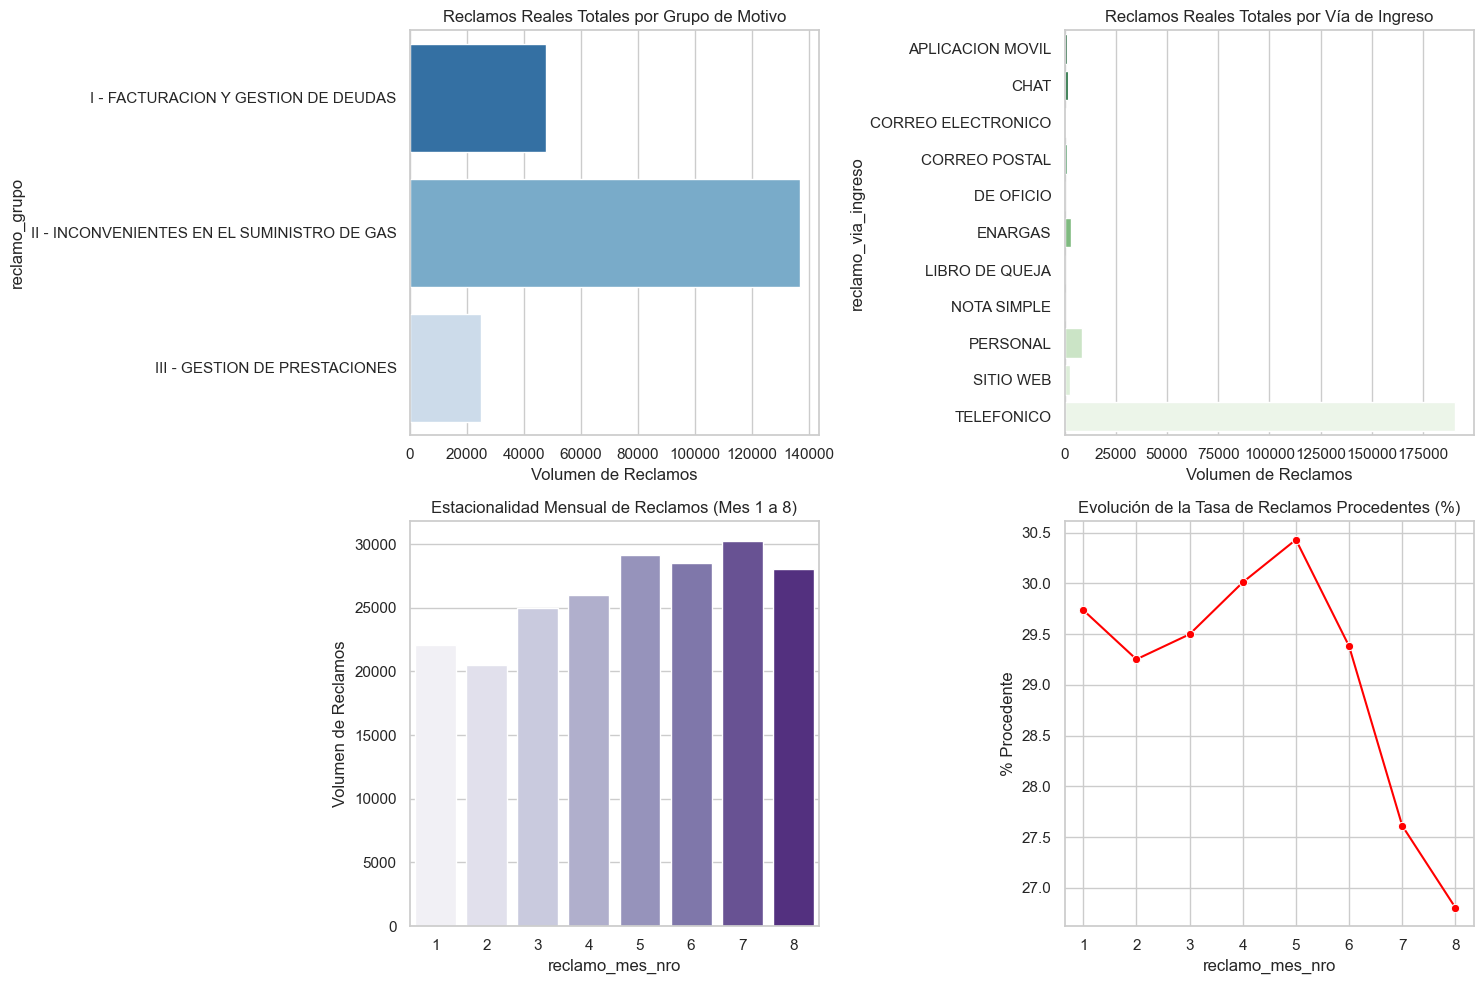

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Reclamos por Grupo
sns.barplot(data=df.groupby('reclamo_grupo')['reclamo_cantidad'].sum().reset_index(), 
            x='reclamo_cantidad', y='reclamo_grupo', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Reclamos Reales Totales por Grupo de Motivo')
axes[0, 0].set_xlabel('Volumen de Reclamos')

# 2. Reclamos por Canal (Vía de Ingreso)
sns.barplot(data=df.groupby('reclamo_via_ingreso')['reclamo_cantidad'].sum().reset_index(), 
            x='reclamo_cantidad', y='reclamo_via_ingreso', ax=axes[0, 1], palette='Greens_r')
axes[0, 1].set_title('Reclamos Reales Totales por Vía de Ingreso')
axes[0, 1].set_xlabel('Volumen de Reclamos')

# 3. Evolución Mensual (Enero a Agosto)
sns.barplot(data=df.groupby('reclamo_mes_nro')['reclamo_cantidad'].sum().reset_index(), 
            x='reclamo_mes_nro', y='reclamo_cantidad', ax=axes[1, 0], palette='Purples')
axes[1, 0].set_title('Estacionalidad Mensual de Reclamos (Mes 1 a 8)')
axes[1, 0].set_ylabel('Volumen de Reclamos')

# 4. Tasa de Procedencia por Mes
tasa_mes = df.groupby('reclamo_mes_nro').apply(
    lambda x: (x[x['reclamo_resolucion'] == 'Procedente']['reclamo_cantidad'].sum() / x['reclamo_cantidad'].sum()) * 100
).reset_index(name='tasa_procedente')
sns.lineplot(data=tasa_mes, x='reclamo_mes_nro', y='tasa_procedente', ax=axes[1, 1], marker='o', color='red')
axes[1, 1].set_title('Evolución de la Tasa de Reclamos Procedentes (%)')
axes[1, 1].set_ylabel('% Procedente')

plt.tight_layout()
plt.show()

In [4]:
# Definición de la partición temporal:
# Meses 1 a 6 (Verano a inicio de Invierno): Entrenamiento
# Meses 7 a 8 (Pico invernal): Prueba / Evaluación
df_train_agregado = df[df['reclamo_mes_nro'] <= 6].copy()
df_test_agregado = df[df['reclamo_mes_nro'] > 6].copy()

print("--- Partición Temporal en Datos Agregados ---")
print(f"Filas Train (Meses 1-6): {len(df_train_agregado)} ({df_train_agregado['reclamo_cantidad'].sum():,} reclamos)")
print(f"Filas Test  (Meses 7-8): {len(df_test_agregado)} ({df_test_agregado['reclamo_cantidad'].sum():,} reclamos)")

# Desagregación controlada CONSERVANDO id_registro_agregado dentro de cada partición
train_expanded = df_train_agregado.loc[df_train_agregado.index.repeat(df_train_agregado['reclamo_cantidad'])].copy()
test_expanded = df_test_agregado.loc[df_test_agregado.index.repeat(df_test_agregado['reclamo_cantidad'])].copy()

train_expanded.reset_index(drop=True, inplace=True)
test_expanded.reset_index(drop=True, inplace=True)

print("\n--- Dimensiones de las Particiones Desagregadas ---")
print(f"Train Reclamos: {train_expanded.shape[0]:,} filas")
print(f"Test Reclamos:  {test_expanded.shape[0]:,} filas")

--- Partición Temporal en Datos Agregados ---
Filas Train (Meses 1-6): 2572 (151,176 reclamos)
Filas Test  (Meses 7-8): 882 (58,315 reclamos)

--- Dimensiones de las Particiones Desagregadas ---
Train Reclamos: 151,176 filas
Test Reclamos:  58,315 filas


### Conclusiones Principales del Análisis Exploratorio:

1. **Volumen Real vs. Filas Agregadas:**
   * El dataset original no contiene reclamos individuales, sino 3.454 resúmenes mensuales que consolidan **209.491 reclamos reales**.
   * A nivel poblacional existe un marcado desbalance: el **70,96% resultaron Improcedentes** y solo el **29,04% Procedentes**.

2. **Hallazgos Clave de las Variables:**
   * **Causa principal:** El 65,27% de las quejas corresponden a *Inconvenientes en el Suministro*.
   * **Canal predominante:** El 90,92% de los reclamos ingresan por vía *Telefónica*.
   * **Estacionalidad:** Las quejas aumentan fuertemente en los meses de frío (julio y agosto), aunque la tasa de procedencia se mantiene estable en torno al 30%.

3. **Decisiones Metodológicas para el Modelado:**
   * **Prevención de Data Leakage:** Se excluye `reclamo_cantidad` de los predictores ($X$) porque es un acumulado mensual posterior a la gestión del reclamo.
   * **Evaluación Temporal Realista:** Para evaluar cómo predecir reclamos futuros, la partición se hace cronológicamente: se entrena con los meses 1 a 6 (151.176 reclamos) y se evalúa con los meses 7 y 8 (58.315 reclamos), evitando mezclar copias de una misma fila entre entrenamiento y prueba.

In [5]:
# Definición de variables predictoras
# Tratamos reclamo_mes_nro como categórica para captar efectos estacionales no lineales
features_categoricas = ['reclamo_mes_nro', 'reclamo_prestadora', 'reclamo_provincia', 'reclamo_grupo', 'reclamo_via_ingreso']

# Variables objetivo
y_train = (train_expanded['reclamo_resolucion'] == 'Procedente').astype(int).values
y_test = (test_expanded['reclamo_resolucion'] == 'Procedente').astype(int).values

# Ajustar OneHotEncoder EXCLUSIVAMENTE sobre Train
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
encoder.fit(train_expanded[features_categoricas])

# Transformación de Train y Test
X_train_encoded = encoder.transform(train_expanded[features_categoricas])
X_test_encoded = encoder.transform(test_expanded[features_categoricas])

nombres_columnas = encoder.get_feature_names_out(features_categoricas)

# Armado de DataFrames finales
df_train_proc = pd.DataFrame(X_train_encoded, columns=nombres_columnas)
df_train_proc['id_registro_agregado'] = train_expanded['id_registro_agregado'].values
df_train_proc['target_procedente'] = y_train

df_test_proc = pd.DataFrame(X_test_encoded, columns=nombres_columnas)
df_test_proc['id_registro_agregado'] = test_expanded['id_registro_agregado'].values
df_test_proc['target_procedente'] = y_test

print(f"Matriz de Train: {df_train_proc.shape[0]:,} filas x {df_train_proc.shape[1]} columnas")
print(f"Matriz de Test:  {df_test_proc.shape[0]:,} filas x {df_test_proc.shape[1]} columnas")

Matriz de Train: 151,176 filas x 50 columnas
Matriz de Test:  58,315 filas x 50 columnas


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [6]:
# Guardar los conjuntos procesados y divididos
df_train_proc.to_csv('../data/processed/train_reclamos_2026.csv', index=False)
df_test_proc.to_csv('../data/processed/test_reclamos_2026.csv', index=False)

print("Conjuntos de entrenamiento y prueba exportados exitosamente en 'data/processed/'.")

Conjuntos de entrenamiento y prueba exportados exitosamente en 'data/processed/'.
